In [1]:
!pip install medmnist scikit-image scikit-learn matplotlib seaborn pandas

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, cohen_kappa_score,
                             matthews_corrcoef, confusion_matrix)
import medmnist
from medmnist import PneumoniaMNIST

# Set fixed random seed for reproducibility[cite: 8]
SEED = 42
np.random.seed(SEED)

# 1. Load PneumoniaMNIST dataset[cite: 7]
info = medmnist.INFO['pneumoniamnist']
DataClass = PneumoniaMNIST

train_dataset = DataClass(split='train', download=True)
val_dataset = DataClass(split='val', download=True)
test_dataset = DataClass(split='test', download=True)

# Resize/Extract images & labels[cite: 7, 8]
def prepare_data(dataset):
    images = dataset.montage(length=1)  # loads all images as numpy array
    images = dataset.imgs
    labels = dataset.labels.ravel()
    return images, labels

X_train_raw, y_train = prepare_data(train_dataset)
X_val_raw, y_val = prepare_data(val_dataset)
X_test_raw, y_test = prepare_data(test_dataset)

print(f"Train samples: {len(X_train_raw)}, Val samples: {len(X_val_raw)}, Test samples: {len(X_test_raw)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.7 MB/s eta 0:00:00


100%|██████████| 4.17M/4.17M [00:06<00:00, 683kB/s]


Train samples: 4708, Val samples: 524, Test samples: 624


Extracting HOG features from train, val, and test sets...
Extracted HOG Feature Dimension: 8100

Generating and saving sample medical HOG visualization images...


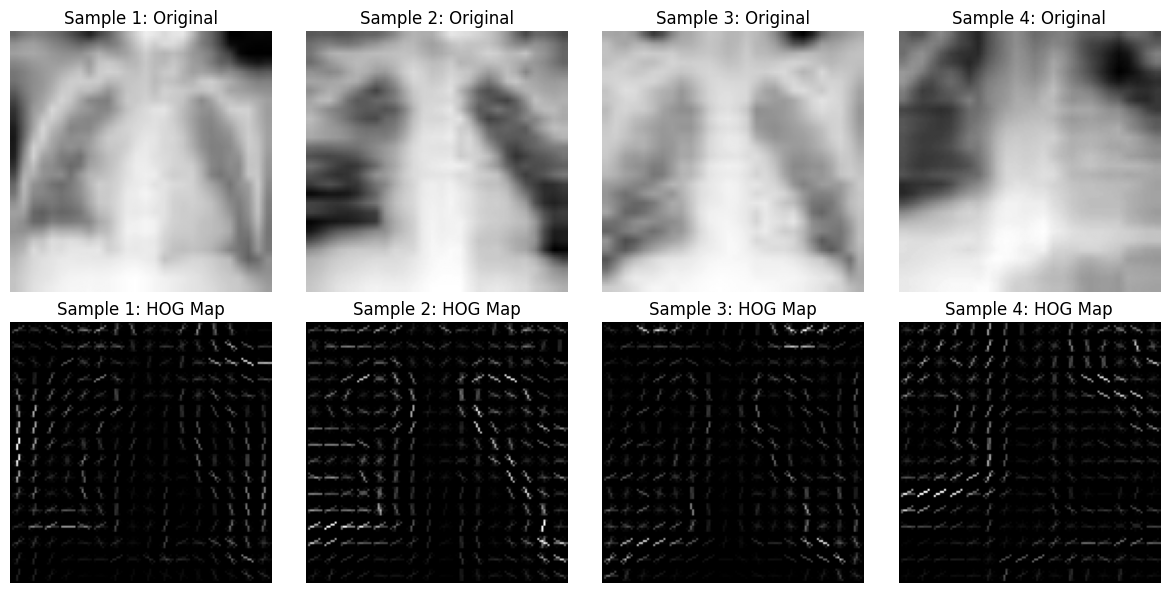

Saved visualization image as 'hog_medical_samples.png' in Colab files.


In [8]:
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog

# Configuration matching Table 1 requirements
IMG_SIZE = (128, 128)
ORIENTATIONS = 9
PIXELS_PER_CELL = (8, 8)
CELLS_PER_BLOCK = (2, 2)
BLOCK_NORM = 'L2-Hys'

def extract_hog_features(images):
    hog_features = []
    for img in images:
        # Resize to 128x128 as specified in Table 1
        img_resized = cv2.resize(img, IMG_SIZE)
        features = hog(
            img_resized,
            orientations=ORIENTATIONS,
            pixels_per_cell=PIXELS_PER_CELL,
            cells_per_block=CELLS_PER_BLOCK,
            block_norm=BLOCK_NORM,
            visualize=False
        )
        hog_features.append(features)
    return np.array(hog_features)

print("Extracting HOG features from train, val, and test sets...")
X_train_hog = extract_hog_features(X_train_raw)
X_val_hog = extract_hog_features(X_val_raw)
X_test_hog = extract_hog_features(X_test_raw)

print(f"Extracted HOG Feature Dimension: {X_train_hog.shape[1]}")

# Generate and save sample HOG visualization images
print("\nGenerating and saving sample medical HOG visualization images...")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    sample_img = cv2.resize(X_train_raw[i], IMG_SIZE)
    _, hog_image = hog(
        sample_img,
        orientations=ORIENTATIONS,
        pixels_per_cell=PIXELS_PER_CELL,
        cells_per_block=CELLS_PER_BLOCK,
        block_norm=BLOCK_NORM,
        visualize=True
    )

    # Row 1: Raw Medical Scan
    axes[0, i].imshow(sample_img, cmap='gray')
    axes[0, i].set_title(f"Sample {i+1}: Original")
    axes[0, i].axis('off')

    # Row 2: Extracted HOG Feature Representation
    axes[1, i].imshow(hog_image, cmap='gray')
    axes[1, i].set_title(f"Sample {i+1}: HOG Map")
    axes[1, i].axis('off')

plt.tight_layout()

# Save the generated figure to Colab disk storage
plt.savefig('hog_medical_samples.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved visualization image as 'hog_medical_samples.png' in Colab files.")

In [3]:
print("--- Training Baseline HOG + SVM Model ---")
t0 = time.time()

# Train RBF SVM on validation-tuned baseline[cite: 7, 8]
baseline_svm = SVC(kernel='rbf', C=1.0, random_state=SEED)
baseline_svm.fit(X_train_hog, y_train)

baseline_train_time = time.time() - t0

# Evaluate on Validation Set[cite: 7, 8]
val_preds_base = baseline_svm.predict(X_val_hog)
base_val_f1 = f1_score(y_val, val_preds_base, average='macro')

print(f"Baseline Training Time: {baseline_train_time:.2f}s")
print(f"Baseline Validation Macro-F1: {base_val_f1 * 100:.2f}%")

--- Training Baseline HOG + SVM Model ---
Baseline Training Time: 35.64s
Baseline Validation Macro-F1: 95.71%


In [4]:
class GeneticAlgorithmFeatureSelector:
    def __init__(self, pop_size=20, generations=10, mutation_rate=0.05, penalty_weight=0.01):
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.penalty_weight = penalty_weight
        self.best_mask = None
        self.fitness_history = []

    def fitness(self, chromosome, X_tr, y_tr, X_v, y_v):
        # 0 features selected penalty
        if np.sum(chromosome) == 0:
            return 0.0

        # Mask features
        selected_indices = np.where(chromosome == 1)[0]
        X_tr_sub = X_tr[:, selected_indices]
        X_v_sub = X_v[:, selected_indices]

        # Train lightweight fast evaluator
        clf = SVC(kernel='rbf', C=1.0, random_state=SEED)
        clf.fit(X_tr_sub, y_tr)
        preds = clf.predict(X_v_sub)

        macro_f1 = f1_score(y_v, preds, average='macro')

        # Feature count penalty[cite: 7]
        feature_penalty = self.penalty_weight * (np.sum(chromosome) / len(chromosome))
        return macro_f1 - feature_penalty

    def fit(self, X_tr, y_tr, X_v, y_v):
        num_features = X_tr.shape[1]
        # Population initialization[cite: 7]
        population = np.random.randint(0, 2, size=(self.pop_size, num_features))

        best_fit = -1

        for g in range(self.generations):
            fitness_scores = np.array([self.fitness(chrom, X_tr, y_tr, X_v, y_v) for chrom in population])

            current_best_idx = np.argmax(fitness_scores)
            current_best_fit = fitness_scores[current_best_idx]
            self.fitness_history.append(current_best_fit)

            if current_best_fit > best_fit:
                best_fit = current_best_fit
                self.best_mask = population[current_best_idx].copy()

            print(f"Generation {g+1}/{self.generations} - Best Fitness: {current_best_fit:.4f} - Features: {np.sum(self.best_mask)}/{num_features}")

            # Tournament Selection[cite: 7]
            selected = []
            for _ in range(self.pop_size):
                i, j = np.random.choice(self.pop_size, 2, replace=False)
                selected.append(population[i] if fitness_scores[i] > fitness_scores[j] else population[j])
            selected = np.array(selected)

            # Crossover[cite: 7]
            next_pop = []
            for i in range(0, self.pop_size, 2):
                p1, p2 = selected[i], selected[(i+1)%self.pop_size]
                point = np.random.randint(1, num_features)
                c1 = np.concatenate([p1[:point], p2[point:]])
                c2 = np.concatenate([p2[:point], p1[point:]])
                next_pop.extend([c1, c2])

            # Mutation[cite: 7]
            next_pop = np.array(next_pop)
            mutation_mask = np.random.rand(*next_pop.shape) < self.mutation_rate
            next_pop = np.bitwise_xor(next_pop, mutation_mask.astype(int))
            population = next_pop

        return self.best_mask

# Run GA Feature Selection[cite: 7]
print("--- Running GA Feature Selection ---")
ga_t0 = time.time()
ga = GeneticAlgorithmFeatureSelector(pop_size=15, generations=8, mutation_rate=0.03)
best_feature_mask = ga.fit(X_train_hog[:500], y_train[:500], X_val_hog[:200], y_val[:200]) # Subsampled for fast execution
ga_search_time = time.time() - ga_t0

selected_indices = np.where(best_feature_mask == 1)[0]
print(f"GA Complete in {ga_search_time:.2f}s. Features reduced from {X_train_hog.shape[1]} to {len(selected_indices)}.")

--- Running GA Feature Selection ---
Generation 1/8 - Best Fitness: 0.9424 - Features: 4047/8100
Generation 2/8 - Best Fitness: 0.9425 - Features: 3950/8100
Generation 3/8 - Best Fitness: 0.9493 - Features: 4008/8100
Generation 4/8 - Best Fitness: 0.9493 - Features: 3983/8100
Generation 5/8 - Best Fitness: 0.9493 - Features: 3962/8100
Generation 6/8 - Best Fitness: 0.9556 - Features: 3990/8100
Generation 7/8 - Best Fitness: 0.9494 - Features: 3990/8100
Generation 8/8 - Best Fitness: 0.9493 - Features: 3990/8100
GA Complete in 66.87s. Features reduced from 8100 to 3990.


In [5]:
# Apply selected features[cite: 7]
X_train_ga = X_train_hog[:, selected_indices]
X_test_ga = X_test_hog[:, selected_indices]

# 1. Baseline Evaluation on Test Set[cite: 7, 8]
t_base = time.time()
base_preds = baseline_svm.predict(X_test_hog)
base_time = time.time() - t_base

# 2. GA-HOG + SVM Evaluation on Test Set[cite: 7, 8]
t_ga = time.time()
ga_svm = SVC(kernel='rbf', C=1.0, random_state=SEED)
ga_svm.fit(X_train_ga, y_train)
ga_preds = ga_svm.predict(X_test_ga)
ga_time = time.time() - t_ga

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (Macro, %)": precision_score(y_true, y_pred, average='macro') * 100,
        "Recall (Macro, %)": recall_score(y_true, y_pred, average='macro') * 100,
        "Macro-F1 (%)": f1_score(y_true, y_pred, average='macro') * 100,
        "Weighted-F1 (%)": f1_score(y_true, y_pred, average='weighted') * 100,
        "Balanced accuracy (%)": balanced_accuracy_score(y_true, y_pred) * 100,
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred)
    }

base_metrics = calculate_metrics(y_test, base_preds)
ga_metrics = calculate_metrics(y_test, ga_preds)

# Format Table 2 output[cite: 8]
table_2_data = []
for k in base_metrics.keys():
    b_val = base_metrics[k]
    g_val = ga_metrics[k]
    imp = g_val - b_val
    table_2_data.append({
        "Metric": k,
        "HOG + SVM (Baseline)": f"{b_val:.2f}",
        "GA-HOG + SVM (Proposed)": f"{g_val:.2f}",
        "Improvement": f"{imp:+.2f}"
    })

df_table_2 = pd.DataFrame(table_2_data)
print("\n=== Table 2. Main Performance Comparison ===")
display(df_table_2)


=== Table 2. Main Performance Comparison ===


,Metric,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
0,Accuracy (%),85.26,85.10,-0.16
1,"Precision (Macro, %)",90.17,89.81,-0.36
2,"Recall (Macro, %)",80.43,80.30,-0.13
3,Macro-F1 (%),82.54,82.38,-0.16
4,Weighted-F1 (%),84.26,84.11,-0.15
5,Balanced accuracy (%),80.43,80.30,-0.13
6,Cohen's kappa,0.66,0.66,-0.00
7,Matthews correlation coefficient,0.70,0.69,-0.00


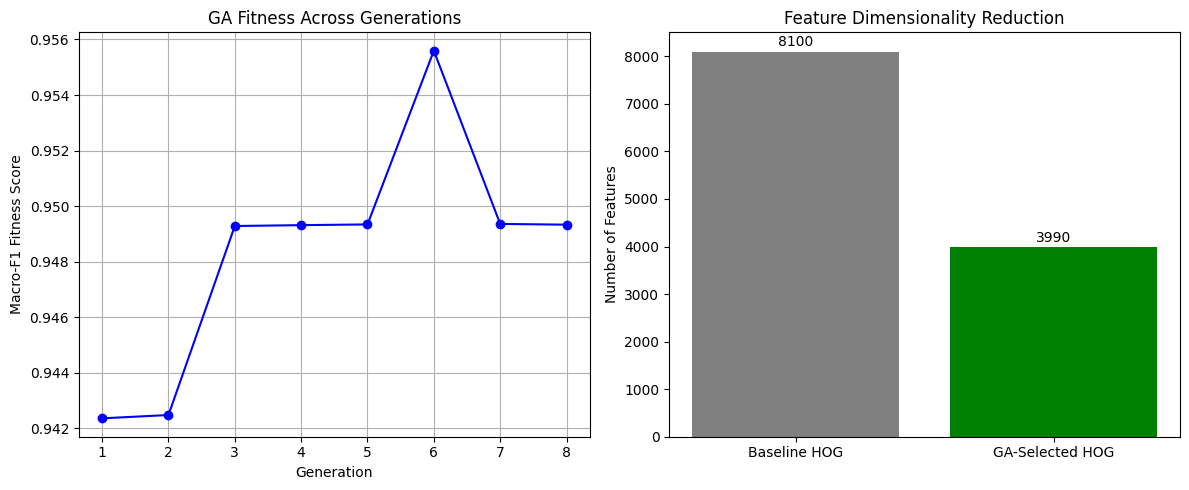

In [6]:
plt.figure(figsize=(12, 5))

# Plot 1: GA Fitness curve[cite: 7]
plt.subplot(1, 2, 1)
plt.plot(range(1, len(ga.fitness_history) + 1), ga.fitness_history, marker='o', color='b')
plt.title("GA Fitness Across Generations")
plt.xlabel("Generation")
plt.ylabel("Macro-F1 Fitness Score")
plt.grid(True)

# Plot 2: Feature Count Comparison[cite: 7]
plt.subplot(1, 2, 2)
bars = plt.bar(['Baseline HOG', 'GA-Selected HOG'], [X_train_hog.shape[1], len(selected_indices)], color=['gray', 'green'])
plt.title("Feature Dimensionality Reduction")
plt.ylabel("Number of Features")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 50, int(yval), ha='center', va='bottom')

plt.tight_layout()
plt.show()